# Monthly feature-importance monitoring

Read the **existing held-out permutation-importance reports** from completed Citi Bike
monthly training runs. No Spark, gold data, SHAP, model loading, or retraining is needed.

Run the cells from top to bottom. The dashboard contains:
1. Run coverage and missing-report warnings.
2. Raw importance and relative-positive-importance heatmaps.
3. Feature trends with shuffle standard deviations.
4. Forecast MAE versus the seven-day-lag baseline.
5. Month-to-month rank changes with algorithm/schema-change flags.
6. An **optional**, explicitly enabled export to a separate MLflow experiment.

**This is a behavioural monitoring dashboard, not a concept-drift test.** Each report
explains that month's train-plus-validation winner on its held-out test month, **not**
the final saved model (which was refitted on that month). Both the model and evaluation
population can change. Algorithm switches, retraining, seasonality, correlated inputs,
and sampling noise can all change importance without concept drift. Rejected winners
are not necessarily models that served production predictions.

In [13]:
%pip install mlflow==3.17.1


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Connect and configure

Open this notebook in the project's Jupyter service (`http://localhost:8888`). It uses
packages already in `requirements.txt`; SHAP is not required. Outside Docker, point
`TRACKING_URI` at `http://localhost:5000`. Inside Compose, the environment supplies
`http://mlflow:5000`.

If your running Jupyter image predates MLflow, run `%pip install mlflow==3.17.1`
in a temporary code cell, then **restart the kernel** before running this notebook.
For a persistent image update, rebuild/recreate only Jupyter from the project root:
`docker compose up -d --build --no-deps jupyter` (this interrupts Jupyter sessions).
Do not install packages into Airflow's base Python.

Start with all monthly winners, including rejected ones. `PROMOTED_ONLY` selects
promoted candidates; it does **not** reconstruct the deployed champion for every month.
Date filters refer to the report's **test-window end**, not the MLflow creation time.

In [14]:
import json
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
try:
    import mlflow
    from mlflow.exceptions import MlflowException
except ImportError as error:
    raise ImportError("Run %pip install mlflow==3.17.1 in this notebook kernel, then restart it.") from error

TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
SOURCE_EXPERIMENT = os.getenv("MLFLOW_EXPERIMENT_NAME", "citibike-demand-forecasting")
START_DATE = None               # Inclusive test-window end, e.g. "2016-06-30"
END_DATE = None                 # Inclusive test-window end, e.g. "2017-09-30"
MODEL_TYPES = []                # Empty = all; e.g. ["xgboost (poisson)"]
PROMOTED_ONLY = False
TOP_FEATURES = 12
TOP_K = 5
TREND_FEATURES = ["fe_lag_1", "fe_lag_7", "fe_rolling_mean_7", "station_id"]
# Display names only: keep canonical model-input and MLflow metric keys unchanged.
FEATURE_LABELS = {"station_id": "Station profile (historical mean + weekend ratio)"}
EXPORT_TO_MLFLOW = False        # Read-only unless you explicitly change this to True
MONITORING_EXPERIMENT = "citibike-feature-monitoring"

mlflow.set_tracking_uri(TRACKING_URI)
client = mlflow.tracking.MlflowClient(tracking_uri=TRACKING_URI)
figures = {}
print("Tracking server:", TRACKING_URI)

Tracking server: http://mlflow:5000


## 2. Read reports and check coverage

Read `training_info.json` (which embeds the report) from every finished, published run.
Search is paginated. Older runs without reports are listed rather than silently treated
as zero. Network/authentication errors are raised, not disguised as missing reports.
Unsupported report methods/units/scopes are excluded. No models are unpickled.

In [15]:
def collect_history(client, experiment_id):
    records, coverage = [], []
    token = None
    while True:
        page = client.search_runs(
            [experiment_id],
            filter_string="attributes.status = 'FINISHED' AND tags.`citibike.ready` = 'true'",
            max_results=1000,
            page_token=token,
        )
        for run in page:
            tags = run.data.tags
            status = {"run_id": run.info.run_id, "cutoff": tags.get("trained_through"),
                      "algorithm": tags.get("model_type")}
            try:
                with tempfile.TemporaryDirectory() as directory:
                    path = client.download_artifacts(run.info.run_id, "training_info.json", directory)
                    info = json.loads(Path(path).read_text())
            except MlflowException as error:
                if error.error_code not in {"RESOURCE_DOES_NOT_EXIST", "NOT_FOUND"}:
                    raise
                coverage.append({**status, "status": "Missing training_info.json"})
                continue
            report = info.get("feature_importance")
            if not report:
                coverage.append({**status, "status": "No importance report (older run)"})
                continue
            compatible = (
                report.get("method") == "permutation"
                and report.get("units") == "increase_in_mae"
                and report.get("model_scope") == "train_validation_refit_before_final_refit"
            )
            if not compatible:
                coverage.append({**status, "status": "Incompatible report method/units/scope"})
                continue
            table = pd.DataFrame(report["features"])
            required = {"feature", "importance_mean", "importance_std"}
            if not required.issubset(table.columns) or table.empty:
                raise ValueError(f"Malformed importance table in {run.info.run_id}")
            if table["feature"].isna().any() or table["feature"].duplicated().any():
                raise ValueError(f"Missing or duplicate feature names in {run.info.run_id}")
            values = table[["importance_mean", "importance_std"]].to_numpy(dtype=float)
            if not np.isfinite(values).all() or (values[:, 1] < 0).any():
                raise ValueError(f"Invalid importance values in {run.info.run_id}")
            window = report.get("test_window", info.get("test_window"))
            if not window or len(window) != 2:
                raise ValueError(f"Missing test window in {run.info.run_id}")
            start, end = pd.Timestamp(window[0]), pd.Timestamp(window[1])
            if pd.isna(start) or pd.isna(end) or start > end:
                raise ValueError(f"Invalid test window in {run.info.run_id}")
            shared = {
                "run_id": run.info.run_id, "algorithm": info["model"],
                "trained_through": info["trained_through"],
                "promoted": tags.get("promoted") == "true",
                "test_start": start, "test_end": end,
                "model_mae": info.get("test_model_mae", np.nan),
                "baseline_mae": info.get("test_baseline_mae", np.nan),
                "sample_baseline_mae": report.get("sample_baseline_mae", np.nan),
                "sample_rows": report.get("sample_rows"), "test_rows": report.get("test_rows"),
                "n_repeats": report.get("n_repeats"), "seed": report.get("seed"),
            }
            records.extend({**shared, **row} for row in table.to_dict("records"))
            coverage.append({**status, "status": "Loaded"})
        token = page.token
        if not token:
            break
    return pd.DataFrame(records), pd.DataFrame(coverage)

experiment = client.get_experiment_by_name(SOURCE_EXPERIMENT)
if experiment is None or experiment.lifecycle_stage != "active":
    raise ValueError(f"No active experiment named {SOURCE_EXPERIMENT!r} on {TRACKING_URI}")
all_history, coverage = collect_history(client, experiment.experiment_id)
display(coverage)
if all_history.empty:
    raise ValueError("No compatible importance reports. Older completed runs are not automatically backfilled.")
print("Coverage:", coverage["status"].value_counts().to_dict())

,run_id,cutoff,algorithm,status
0,aed58ea926ad4f45a11e0243b106851e,2017-09-30,random forest,Loaded
1,6f2f5bebd3cb455cb98982ee9ee57802,2017-08-31,xgboost (poisson),Loaded
2,21ad39960be149dcb8e19b6f38a97f7c,2017-07-31,random forest,Loaded
3,f44fe5bccc434e0989d1862523d49ca3,2017-06-30,xgboost (poisson),Loaded
4,981d4c7fe9544f9d9ea964eb94fb9296,2017-05-31,xgboost (poisson),Loaded
5,a07d58f105d74fd98693e0c5ecc43aba,2017-04-30,xgboost (poisson),Loaded
6,29e8e0b3955648aaa0ee9c54708e17de,2017-03-31,xgboost (poisson),Loaded
7,4a4244fb5a2b4aa6b940aa8193f901ea,2017-02-28,xgboost (poisson),Loaded
8,ba44cafc00b64a89854e32466891eb83,2017-01-31,xgboost (poisson),Loaded
9,cb2d933c665a4517806f0ad75d010ab4,2016-12-31,xgboost (poisson),Loaded


Coverage: {'Loaded': 16}


In [16]:
history = all_history.copy()
if START_DATE is not None:
    history = history.loc[history["test_end"] >= pd.Timestamp(START_DATE)]
if END_DATE is not None:
    history = history.loc[history["test_end"] <= pd.Timestamp(END_DATE)]
if MODEL_TYPES:
    history = history.loc[history["algorithm"].isin(MODEL_TYPES)]
if PROMOTED_ONLY:
    history = history.loc[history["promoted"]]
if history.empty:
    raise ValueError("No reports match the configured filters.")
if TOP_FEATURES < 1 or TOP_K < 1:
    raise ValueError("TOP_FEATURES and TOP_K must be positive.")

metadata_columns = [c for c in history if c not in {"feature", "importance_mean", "importance_std"}]
summary = (history[metadata_columns].drop_duplicates("run_id")
           .sort_values(["test_end", "trained_through", "run_id"]).set_index("run_id"))
summary["period"] = [
    f"{row.test_end:%Y-%m-%d} | {row.algorithm} | {run_id[:8]}"
    for run_id, row in summary.iterrows()
]
importance = history.pivot(index="run_id", columns="feature", values="importance_mean").reindex(summary.index)
shuffle_std = history.pivot(index="run_id", columns="feature", values="importance_std").reindex_like(importance)
feature_order = importance.mean().sort_values(ascending=False).index
importance = importance[feature_order]
shuffle_std = shuffle_std[feature_order]
summary["mae_vs_baseline_ratio"] = summary["model_mae"] / summary["baseline_mae"].where(summary["baseline_mae"] > 0)
display(summary)
print("Missing feature measurements:", int(importance.isna().sum().sum()))
if summary["test_end"].duplicated().any():
    print("WARNING: multiple runs share a test-window end. They remain separate; inspect before comparing changes.")
if len(summary) < 2:
    print("Only one report is selected; temporal change needs at least two reports.")

,algorithm,trained_through,promoted,test_start,test_end,model_mae,baseline_mae,sample_baseline_mae,sample_rows,test_rows,n_repeats,seed,period,mae_vs_baseline_ratio
run_id,,,,,,,,,,,,,,
307fd2b320b04a9cb8f6a539905dde7c,xgboost (poisson),2016-06-30,True,2016-06-01,2016-06-30,15.512,20.651,16.816839,1000,14194,3,20160630,2016-06-30 | xgboost (poisson) | 307fd2b3,0.751150
cb1e13ded5e4490199adc9c5070a69bb,xgboost (poisson),2016-07-31,False,2016-07-01,2016-07-31,15.103,20.763,14.383951,1000,14761,3,20160731,2016-07-31 | xgboost (poisson) | cb1e13de,0.727400
f19b67a7d3654be8aeef729163808e88,xgboost (poisson),2016-08-31,False,2016-08-01,2016-08-31,14.822,19.827,14.894987,1000,15966,3,20160831,2016-08-31 | xgboost (poisson) | f19b67a7,0.747566
dc1ff6b9bb864ac0affdbbe3d8087ff7,xgboost (poisson),2016-09-30,True,2016-09-01,2016-09-30,15.749,24.917,15.287719,1000,17776,3,20160930,2016-09-30 | xgboost (poisson) | dc1ff6b9,0.632058
3434485f6f9f42be9e0aefa926f24819,xgboost (poisson),2016-10-31,False,2016-10-01,2016-10-31,14.208,25.976,14.637787,1000,18801,3,20161031,2016-10-31 | xgboost (poisson) | 3434485f,0.546966
2b52e7ccab304e70bd0fe680bdd02205,xgboost (poisson),2016-11-30,True,2016-11-01,2016-11-30,13.751,27.063,14.084188,1000,18009,3,20161130,2016-11-30 | xgboost (poisson) | 2b52e7cc,0.508111
cb2d933c665a4517806f0ad75d010ab4,xgboost (poisson),2016-12-31,False,2016-12-01,2016-12-31,11.951,17.600,11.668908,1000,18605,3,20161231,2016-12-31 | xgboost (poisson) | cb2d933c,0.679034
ba44cafc00b64a89854e32466891eb83,xgboost (poisson),2017-01-31,True,2017-01-01,2017-01-31,10.666,14.507,11.078929,1000,18662,3,20170131,2017-01-31 | xgboost (poisson) | ba44cafc,0.735231
4a4244fb5a2b4aa6b940aa8193f901ea,xgboost (poisson),2017-02-28,False,2017-02-01,2017-02-28,10.257,21.794,10.007090,1000,16896,3,20170228,2017-02-28 | xgboost (poisson) | 4a4244fb,0.470634


Missing feature measurements: 0


## 3. Monthly heatmaps

Columns are chronological **evaluation windows**, labelled with the algorithm and run ID.
The first heatmap preserves negative importance and original MAE units. Grey means
**missing**, not zero. The second divides each positive importance by that run's sum of
positive importances; a run with no positive scores stays grey. These shares are **not**
percentages of accuracy or explained demand. They can hide magnitude changes, so keep
both charts. Raw row order uses average importance across the selected reports.

**Station profile (historical mean + weekend ratio)** is the display name for
the pipeline input `station_id`. The raw ID is replaced with those two training-only
statistics before the estimator sees it. Its importance measures both together by
shuffling the lookup key, not the effect of the ID's numeric/text value. Tables shown
below use this display name; underlying data and CSVs retain `station_id` for traceability.

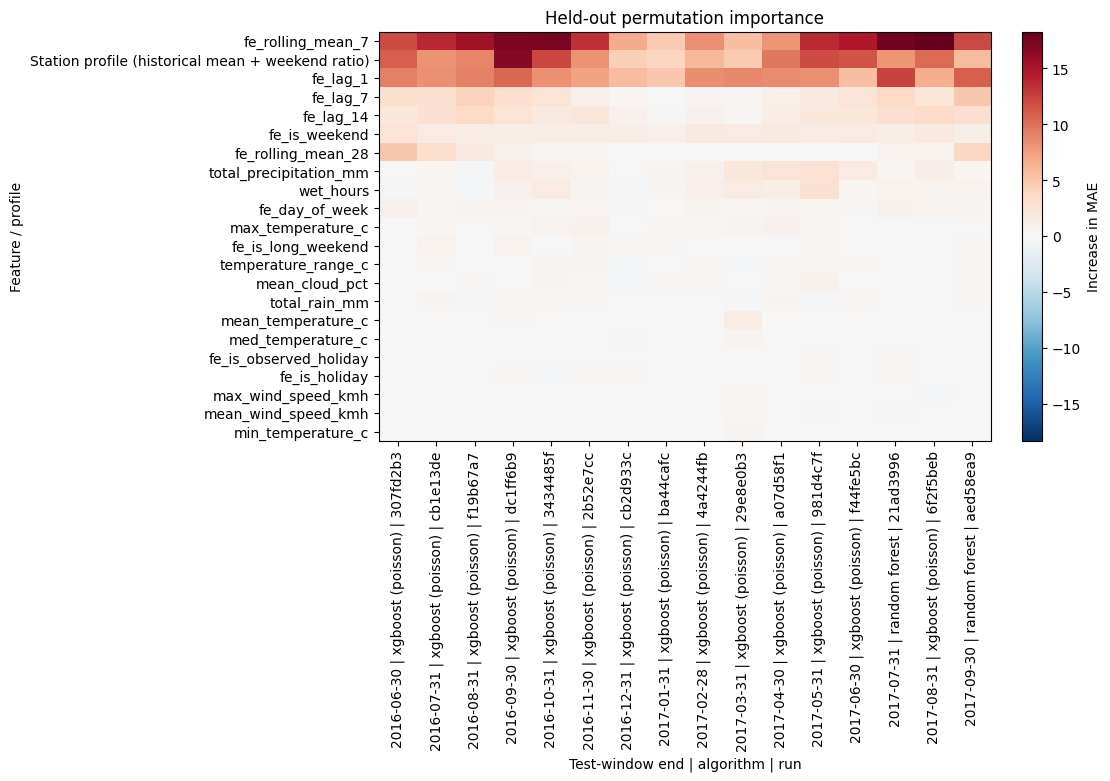

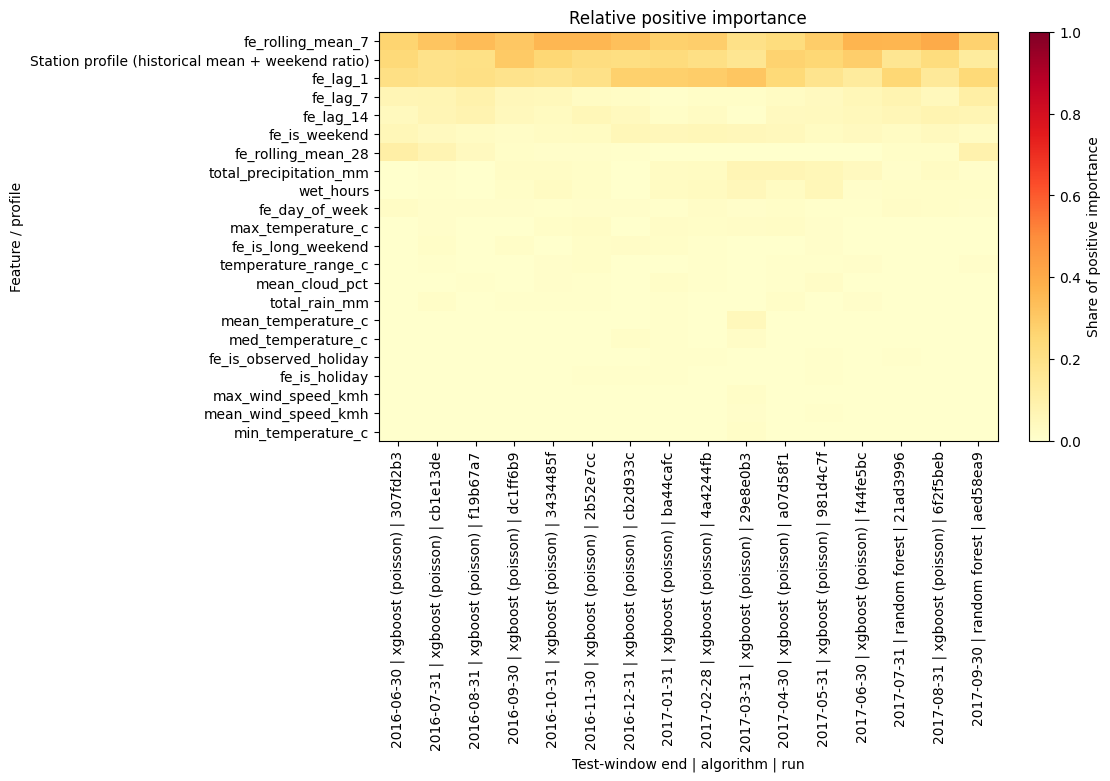

In [17]:
def heatmap(table, title, color_label, relative=False):
    fig, ax = plt.subplots(figsize=(max(11, len(table) * 0.65), max(5, len(table.columns) * 0.35)),
                           constrained_layout=True)
    cmap = plt.get_cmap("YlOrRd" if relative else "RdBu_r").copy()
    cmap.set_bad("lightgrey")
    limit = float(np.nanmax(np.abs(table.to_numpy()))) if table.notna().any().any() else 1.0
    image = ax.imshow(np.ma.masked_invalid(table.to_numpy(dtype=float).T), aspect="auto", cmap=cmap,
                      vmin=0 if relative else -(limit or 1.0), vmax=1 if relative else (limit or 1.0))
    ax.set_xticks(range(len(table)), summary.loc[table.index, "period"], rotation=90)
    ax.set_yticks(range(len(table.columns)), table.rename(columns=FEATURE_LABELS).columns)
    ax.set(title=title, xlabel="Test-window end | algorithm | run", ylabel="Feature / profile")
    fig.colorbar(image, ax=ax, label=color_label)
    return fig

figures["raw_importance"] = heatmap(importance, "Held-out permutation importance", "Increase in MAE")
positive = importance.clip(lower=0)
positive_total = positive.sum(axis=1, min_count=1)
relative = positive.div(positive_total.where(positive_total > 0), axis=0)
figures["relative_importance"] = heatmap(relative, "Relative positive importance", "Share of positive importance", relative=True)
plt.show()

## 4. Feature trends and uncertainty

Choose inputs in `TREND_FEATURES`. Thin grey vertical lines mark an algorithm switch.
Each point is one report; missing features leave a gap. Error bars are **standard
deviations across shuffles**, not confidence intervals and not sampling uncertainty
across days/stations. Current training uses at most 1,000 rows and three repeats, so
small differences may be noisy. Hovering is not required: run IDs are in the table above.

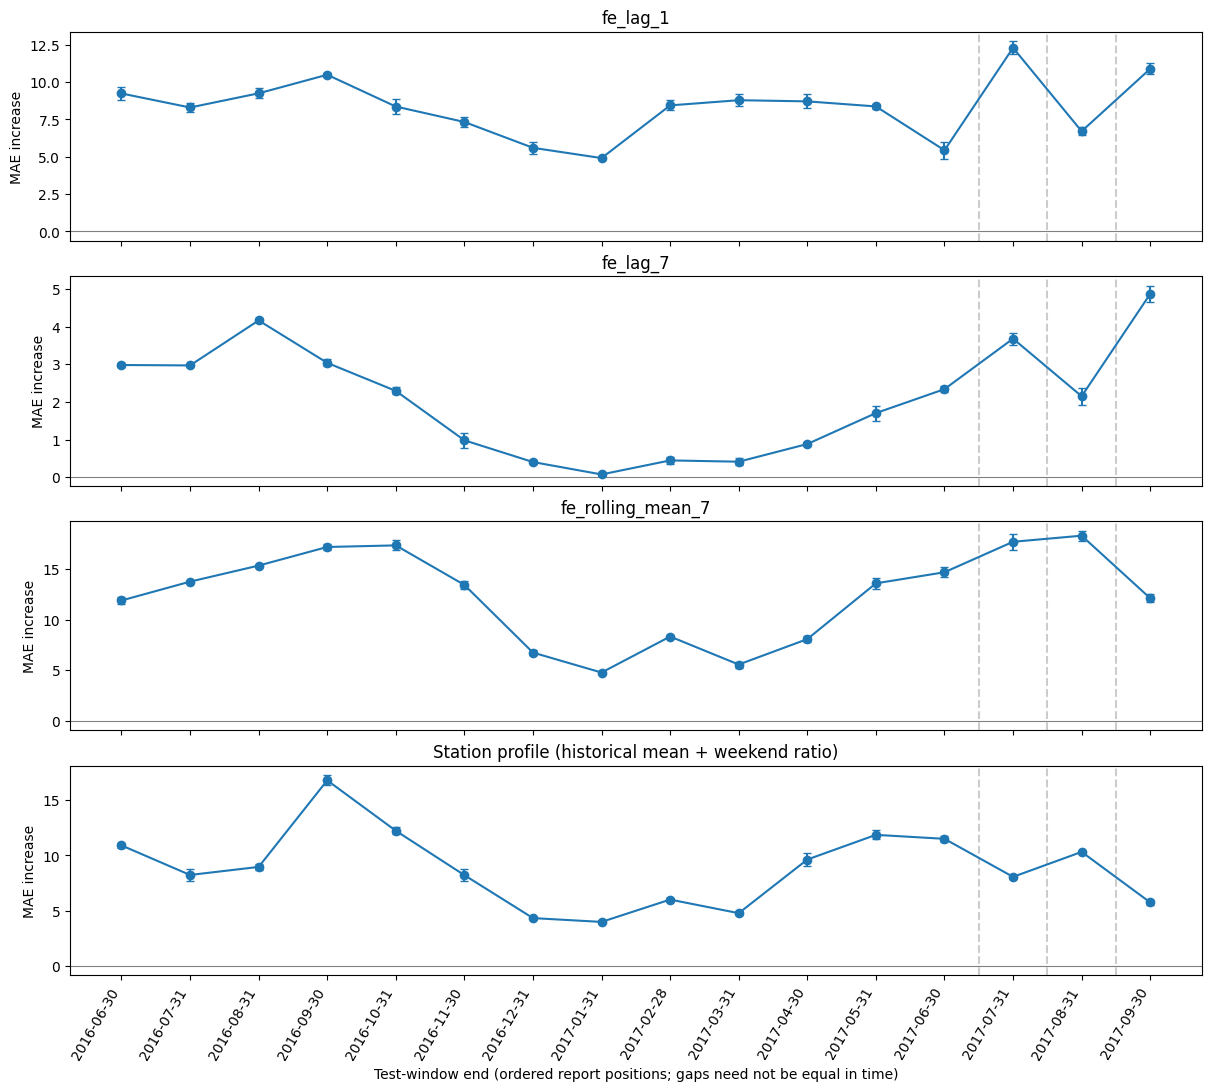

In [18]:
selected_features = [f for f in TREND_FEATURES if f in importance.columns]
missing_requested = sorted(set(TREND_FEATURES) - set(selected_features))
if missing_requested:
    print("Requested features absent from all selected reports:", missing_requested)
algorithm_changed = summary["algorithm"].ne(summary["algorithm"].shift())
algorithm_changed.iloc[0] = False
x = np.arange(len(summary))
if selected_features:
    fig, axes = plt.subplots(len(selected_features), 1, figsize=(12, 2.7 * len(selected_features)),
                             sharex=True, squeeze=False, constrained_layout=True)
    for ax, feature in zip(axes.flat, selected_features):
        ax.errorbar(x, importance[feature], yerr=shuffle_std[feature], marker="o", capsize=3)
        ax.axhline(0, color="grey", linewidth=0.8)
        for position in x[algorithm_changed.to_numpy()]:
            ax.axvline(position - 0.5, color="grey", alpha=0.4, linestyle="--")
        ax.set(title=FEATURE_LABELS.get(feature, feature), ylabel="MAE increase")
    axes[-1, 0].set_xticks(x, summary["test_end"].dt.strftime("%Y-%m-%d"), rotation=60, ha="right")
    axes[-1, 0].set_xlabel("Test-window end (ordered report positions; gaps need not be equal in time)")
    figures["feature_trends"] = fig
    plt.show()
else:
    print("Choose TREND_FEATURES from:", importance.columns.tolist())

### Combined feature trends — one shared scale

Compare the same selected features on one chart. Each coloured line represents a
feature; all lines use the same MAE-increase axis, without normalization or summing.
Higher values mean greater measured reliance in that month's evaluated model, not
better forecast accuracy. Error bars remain shuffle standard deviations (not confidence
intervals), and dashed lines mark algorithm switches. Correlated inputs can substitute
for one another; these individual importance scores are not additive.

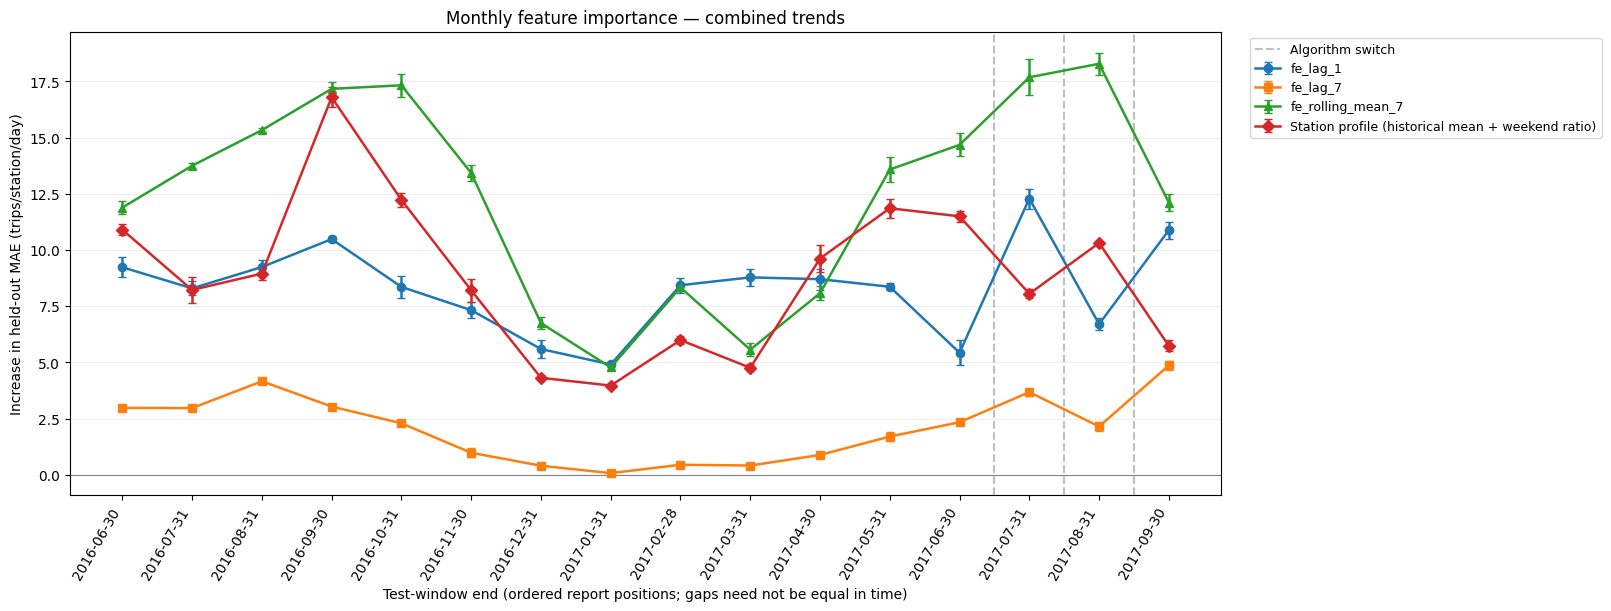

In [19]:
if selected_features:
    fig, ax = plt.subplots(figsize=(16, 6), constrained_layout=True)
    markers = ["o", "s", "^", "D"]
    for index, feature in enumerate(selected_features):
        ax.errorbar(
            x, importance[feature], yerr=shuffle_std[feature],
            marker=markers[index % len(markers)], linewidth=1.8, capsize=3,
            label=FEATURE_LABELS.get(feature, feature),
        )
    ax.axhline(0, color="grey", linewidth=0.8)
    for index, position in enumerate(x[algorithm_changed.to_numpy()]):
        ax.axvline(position - 0.5, color="grey", alpha=0.5, linestyle="--",
                   label="Algorithm switch" if index == 0 else "_nolegend_")
    ax.set_xticks(x, summary["test_end"].dt.strftime("%Y-%m-%d"), rotation=60, ha="right")
    ax.set(
        title="Monthly feature importance — combined trends",
        ylabel="Increase in held-out MAE (trips/station/day)",
        xlabel="Test-window end (ordered report positions; gaps need not be equal in time)",
    )
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
    figures["feature_trends_combined"] = fig
    plt.show()
else:
    print("No selected features to plot. Check TREND_FEATURES and run the trend cell above.")

## 5. Forecast quality alongside importance

The full-test-window MAEs below describe the **same evaluated model** as its importance
report, but the importance baseline MAE uses only the sampled rows. Do not divide by a
full-month MAE to claim an exact relative shuffle effect. MAE/baseline below 1 means the
model beats `fe_lag_7`; above 1 means the lag-7 baseline wins. Seasonal changes in demand
can affect both errors, and a deteriorating baseline can mask rising absolute errors.

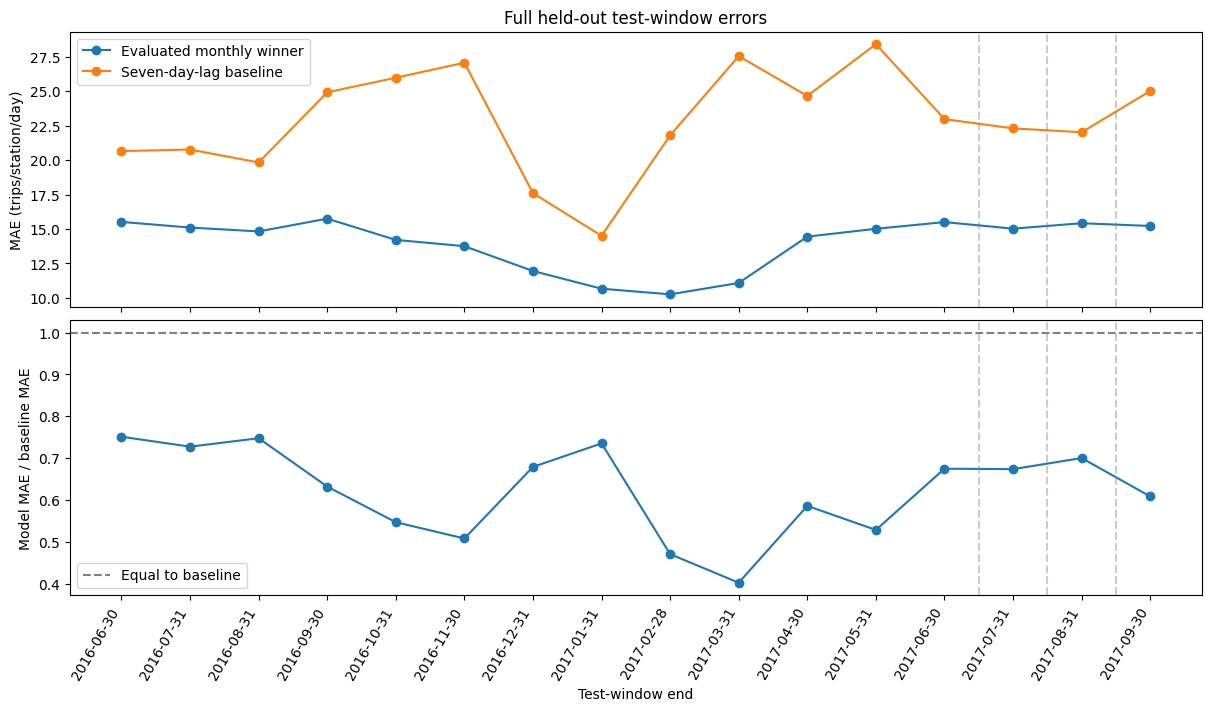

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
axes[0].plot(x, summary["model_mae"], marker="o", label="Evaluated monthly winner")
axes[0].plot(x, summary["baseline_mae"], marker="o", label="Seven-day-lag baseline")
axes[0].set(title="Full held-out test-window errors", ylabel="MAE (trips/station/day)")
axes[0].legend()
axes[1].plot(x, summary["mae_vs_baseline_ratio"], marker="o")
axes[1].axhline(1, color="grey", linestyle="--", label="Equal to baseline")
axes[1].set(ylabel="Model MAE / baseline MAE", xlabel="Test-window end")
axes[1].legend()
axes[1].set_xticks(x, summary["test_end"].dt.strftime("%Y-%m-%d"), rotation=60, ha="right")
for ax in axes:
    for position in x[algorithm_changed.to_numpy()]:
        ax.axvline(position - 0.5, color="grey", alpha=0.4, linestyle="--")
figures["performance"] = fig
plt.show()

## 6. Investigate rank changes, not automatic drift alerts

Compare consecutive available reports: rank correlation (1 = same ranking) and the
Jaccard overlap of the top-K **positive** features (1 = same set). Ties at the K boundary
are broken alphabetically, so small tied/noisy values can change overlap. Correlation
is undefined for constant ranks or fewer than two shared inputs. Schema changes make
rank comparisons non-comparable: keep those scores missing rather than impute zeros.
Missing months/duplicate windows, algorithm switches, and sampling-budget changes are
flagged. Even with identical schemas, these diagnostics do not isolate concept drift.

In [11]:
def rank_changes(importance, summary, top_k):
    rows = []
    for position in range(1, len(summary)):
        previous, current = summary.index[position - 1:position + 1]
        before, after = importance.loc[previous].dropna(), importance.loc[current].dropna()
        schema_changed = set(before.index) != set(after.index)
        shared = sorted(set(before.index) & set(after.index))
        correlation = np.nan
        if not schema_changed and len(shared) >= 2:
            left, right = before[shared].rank(), after[shared].rank()
            if left.nunique() > 1 and right.nunique() > 1:
                correlation = left.corr(right)
        def top_positive(values):
            ordered = values.sort_index().sort_values(ascending=False, kind="stable")
            return set(ordered[ordered > 0].head(top_k).index)
        first, second = top_positive(before), top_positive(after)
        union = first | second
        overlap = len(first & second) / len(union) if union and not schema_changed else np.nan
        old, new = summary.loc[previous], summary.loc[current]
        budgets_changed = any(
            pd.isna(old[field]) or pd.isna(new[field]) or old[field] != new[field]
            for field in ["sample_rows", "n_repeats"]
        )
        month_gap = new.test_end.to_period("M").ordinal - old.test_end.to_period("M").ordinal
        rows.append({
            "previous_run": previous, "run_id": current, "test_end": new.test_end,
            "rank_correlation": correlation, "top_k_positive_jaccard": overlap,
            "shared_features": len(shared), "schema_changed": schema_changed,
            "algorithm_changed": old.algorithm != new.algorithm,
            "sampling_budget_changed_or_unknown": budgets_changed,
            "nonconsecutive_or_duplicate_month": month_gap != 1,
        })
    return pd.DataFrame(rows)

changes = rank_changes(importance, summary, TOP_K)
display(changes)
display(importance.rank(axis=1, ascending=False, method="min")[list(feature_order[:TOP_FEATURES])]
        .rename(columns=FEATURE_LABELS))

,previous_run,run_id,test_end,rank_correlation,top_k_positive_jaccard,shared_features,schema_changed,algorithm_changed,sampling_budget_changed_or_unknown,nonconsecutive_or_duplicate_month
0,307fd2b320b04a9cb8f6a539905dde7c,cb1e13ded5e4490199adc9c5070a69bb,2016-07-31,0.699266,1.000000,22,False,False,False,False
1,cb1e13ded5e4490199adc9c5070a69bb,f19b67a7d3654be8aeef729163808e88,2016-08-31,0.668740,0.666667,22,False,False,False,False
2,f19b67a7d3654be8aeef729163808e88,dc1ff6b9bb864ac0affdbbe3d8087ff7,2016-09-30,0.551159,1.000000,22,False,False,False,False
3,dc1ff6b9bb864ac0affdbbe3d8087ff7,3434485f6f9f42be9e0aefa926f24819,2016-10-31,0.779785,1.000000,22,False,False,False,False
4,3434485f6f9f42be9e0aefa926f24819,2b52e7ccab304e70bd0fe680bdd02205,2016-11-30,0.864483,0.666667,22,False,False,False,False
5,2b52e7ccab304e70bd0fe680bdd02205,cb2d933c665a4517806f0ad75d010ab4,2016-12-31,0.639752,1.000000,22,False,False,False,False
6,cb2d933c665a4517806f0ad75d010ab4,ba44cafc00b64a89854e32466891eb83,2017-01-31,0.477132,0.666667,22,False,False,False,False
7,ba44cafc00b64a89854e32466891eb83,4a4244fb5a2b4aa6b940aa8193f901ea,2017-02-28,0.823828,1.000000,22,False,False,False,False
8,4a4244fb5a2b4aa6b940aa8193f901ea,29e8e0b3955648aaa0ee9c54708e17de,2017-03-31,0.551159,0.666667,22,False,False,False,False
9,29e8e0b3955648aaa0ee9c54708e17de,a07d58f105d74fd98693e0c5ecc43aba,2017-04-30,0.588002,1.000000,22,False,False,False,False


feature,fe_rolling_mean_7,station_id,fe_lag_1,fe_lag_7,fe_lag_14,fe_is_weekend,fe_rolling_mean_28,total_precipitation_mm,wet_hours,fe_day_of_week,max_temperature_c,fe_is_long_weekend
run_id,,,,,,,,,,,,
307fd2b320b04a9cb8f6a539905dde7c,1.0,2.0,3.0,5.0,7.0,6.0,4.0,10.0,22.0,8.0,14.0,11.0
cb1e13ded5e4490199adc9c5070a69bb,1.0,3.0,2.0,5.0,6.0,7.0,4.0,12.0,14.0,11.0,10.0,8.0
f19b67a7d3654be8aeef729163808e88,1.0,3.0,2.0,4.0,5.0,7.0,6.0,22.0,20.0,8.0,11.0,13.0
dc1ff6b9bb864ac0affdbbe3d8087ff7,1.0,2.0,3.0,4.0,5.0,7.0,8.0,6.0,9.0,11.0,15.0,10.0
3434485f6f9f42be9e0aefa926f24819,1.0,2.0,3.0,4.0,5.0,7.0,12.0,8.0,6.0,14.0,9.0,18.0
2b52e7ccab304e70bd0fe680bdd02205,1.0,2.0,3.0,6.0,4.0,5.0,12.0,8.0,9.0,13.0,7.0,10.0
cb2d933c665a4517806f0ad75d010ab4,1.0,3.0,2.0,6.0,5.0,4.0,11.0,16.0,21.0,9.0,12.0,7.0
ba44cafc00b64a89854e32466891eb83,2.0,3.0,1.0,17.0,8.0,4.0,21.0,6.0,5.0,16.0,7.0,10.0
4a4244fb5a2b4aa6b940aa8193f901ea,2.0,3.0,1.0,9.0,7.0,4.0,19.0,6.0,5.0,8.0,10.0,14.0


## 7. Optional: publish this dashboard snapshot to MLflow

Set `EXPORT_TO_MLFLOW = True` in setup and rerun. This creates a **new run** under
`citibike-feature-monitoring`; it never appends to a training run or changes registry
aliases/models. Open the new run's **Artifacts → monitoring** for PNG charts, CSVs,
and provenance. Each execution is a new snapshot, not an automatically refreshing view.
The export includes source run IDs, windows, sampling settings, filters and caveats.

In [10]:
if EXPORT_TO_MLFLOW:
    if MONITORING_EXPERIMENT == SOURCE_EXPERIMENT:
        raise ValueError("Use a separate monitoring experiment, not the training experiment.")
    if mlflow.active_run() is not None:
        raise RuntimeError("End the active MLflow run before exporting this dashboard.")
    mlflow.set_experiment(MONITORING_EXPERIMENT)
    with mlflow.start_run(run_name=f"importance-overview-through-{summary.test_end.max():%Y-%m-%d}") as monitoring_run:
        mlflow.set_tags({"purpose": "feature_importance_monitoring", "source_experiment": SOURCE_EXPERIMENT,
                         "explanation_scope": "monthly_pre_final_refit_winners"})
        for name, figure in figures.items():
            mlflow.log_figure(figure, f"monitoring/{name}.png")
        tables = {"importance_history": history, "run_summary": summary, "coverage": coverage,
                  "raw_importance": importance, "relative_positive_importance": relative,
                  "shuffle_standard_deviation": shuffle_std, "rank_changes": changes}
        for name, table in tables.items():
            mlflow.log_text(table.to_csv(index=True), f"monitoring/{name}.csv")
        mlflow.log_dict({
            "source_experiment": SOURCE_EXPERIMENT, "source_run_ids": summary.index.tolist(),
            "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
            "filters": {"start_date": START_DATE, "end_date": END_DATE,
                        "model_types": MODEL_TYPES, "promoted_only": PROMOTED_ONLY},
            "top_k": TOP_K, "trend_features": TREND_FEATURES,
            "feature_display_names": FEATURE_LABELS,
            "caveats": ["Different model and test population each month; not a concept-drift test.",
                        "Reports explain pre-final-refit winners, not saved final or necessarily deployed models.",
                        "Shuffle standard deviation is not a confidence interval.",
                        "Correlated inputs and seasonality can change importance."],
        }, "monitoring/provenance.json")
        print("Saved monitoring snapshot:", monitoring_run.info.run_id)
        print("Open MLflow > Experiments >", MONITORING_EXPERIMENT, "> latest run > Artifacts > monitoring")
else:
    print("Read-only preview. Set EXPORT_TO_MLFLOW = True to save a new monitoring snapshot.")

Read-only preview. Set EXPORT_TO_MLFLOW = True to save a new monitoring snapshot.


## How to use this every month

1. Wait for monthly training to complete, then **Restart Kernel and Run All Cells**.
2. Check coverage and sampling budgets first. Read raw and relative heatmaps together.
3. Inspect large/persistent changes alongside algorithm switches and MAE/baseline.
4. Compare the same season last year when enough history exists. Do not set arbitrary
   alert thresholds from a few observations; establish typical variability first.
5. Investigate with the existing [single-model explanation notebook](model_feature_importance.ipynb).

**Not measured here:** input-distribution drift, changes in production-champion errors,
or concept drift directly. Summing correlated features' individual scores is not grouped
permutation importance. The single-model notebook can jointly shuffle feature families.
A stronger next step is to evaluate **one frozen reference model** on each subsequent
labelled window and compare errors, grouped importance, input distributions, and station
segments. This removes model-update effects, but still requires seasonal/noise checks.